<a href="https://colab.research.google.com/github/mullinskatie7-source/katherine-mullins.github.io/blob/main/Katherine_Mullins_Coolant_Additive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step 1: Markdown
# Engine Coolant Additive

**Engineer:** Katherine Mullins

**Completion Date:** 10/20/2026

**Class:** EGN3443

**Assignment #:** 10

**Tool Used:** Colab / Python

## Problem Description

The objective of this analysis is to determine whether the new coolant additive significantly reduces mean peak engine temperature.

Each of the 10 vehicles was tested once using the standard coolant mixture and again after the additive was introduced. Since each after-treatment measurement corresponds directly to a before-treatment measurement from the same vehicle, a paired statistical analysis is appropriate.

The differences were defined as:
$$
d= T_{before}- T_{after}
$$

A positive difference therefore indicates a reduction in temperature after using the additive.

The hypotheses are:
$$
H_0: μd=0
$$

$$
H_0: μd>0
$$

where μd is the population mean temperature reduction.
## Methodology

A paired one-tailed t-test was used because the same vehicles were measured before and after treatment and the population standard deviation of the paired differences is unknown.

For each vehicle, the after-additive temperature was subtracted from the before-additive temperature. The mean and standard deviation of these differences were then calculated. The paired t-statistic was determined using:


$$
t = \frac{\bar{d}}{\frac{s_d}{\sqrt{n}}}
$$


where:

- $\bar{d}$ = mean paired difference
- $s_d$ = standard deviation of the paired differences
- $n$ = number of paired observations

The significance level was set to:

$$
α=0.05
$$

If the calculated p-value was less than 0.05, the null hypothesis was rejected.


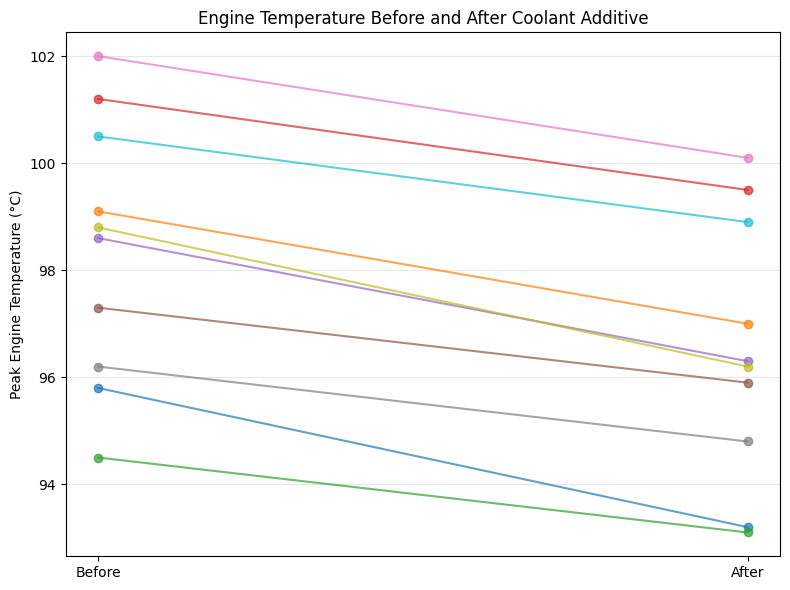

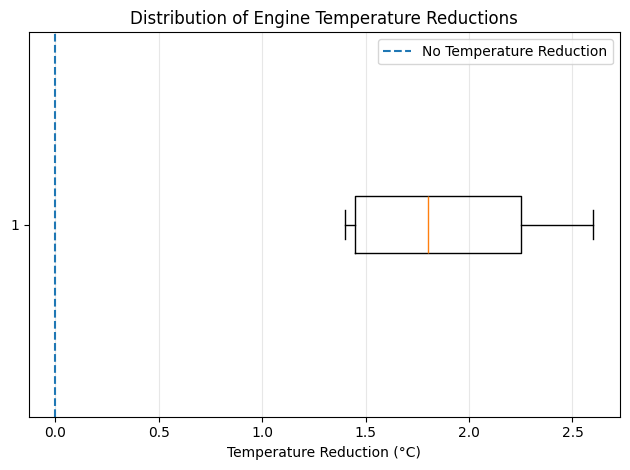

Mean before: 98.400 °C
Mean after: 96.500 °C
Mean reduction: 1.900 °C
Standard deviation of differences: 0.478 °C
t statistic: 12.559
Degrees of freedom: 9
One-tailed p-value: 0.0000002611
Reject H0
There is significant evidence that the additive reduces temperature.


In [1]:
# Step 2: Import required modules and define constants
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

before = np.array([
    95.8, 99.1, 94.5, 101.2, 98.6,
    97.3, 102.0, 96.2, 98.8, 100.5
])

after = np.array([
    93.2, 97.0, 93.1, 99.5, 96.3,
    95.9, 100.1, 94.8, 96.2, 98.9
])

# Step 3: Paired before-and-after plot
plt.figure(figsize=(8, 6))

for i in range(len(before)):
    plt.plot(
        ["Before", "After"],
        [before[i], after[i]],
        marker="o",
        alpha=0.7
    )

plt.title("Engine Temperature Before and After Coolant Additive")
plt.ylabel("Peak Engine Temperature (°C)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Step 4: Box plot of reductions
differences = before - after

plt.boxplot(
    differences,
    vert=False
)

plt.axvline(
    0,
    linestyle="--",
    label="No Temperature Reduction"
)

plt.title("Distribution of Engine Temperature Reductions")
plt.xlabel("Temperature Reduction (°C)")
plt.legend()
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

n = len(differences)
mean_difference = np.mean(differences)
std_difference = np.std(differences, ddof=1)
standard_error = std_difference / np.sqrt(n)

t_stat = mean_difference / standard_error
df = n - 1

p_value = stats.t.sf(t_stat, df)

print(f"Mean before: {np.mean(before):.3f} °C")
print(f"Mean after: {np.mean(after):.3f} °C")
print(f"Mean reduction: {mean_difference:.3f} °C")
print(f"Standard deviation of differences: {std_difference:.3f} °C")
print(f"t statistic: {t_stat:.3f}")
print(f"Degrees of freedom: {df}")
print(f"One-tailed p-value: {p_value:.10f}")

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("There is significant evidence that the additive reduces temperature.")
else:
    print("Fail to reject H0")
